# 1 - Setup

In [1]:
import os
import json
import time
import subprocess
from base64 import b64decode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile

import tensorflow as tf

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


- Lab 6 only runs the int8 model, so we need TensorFlow for the TFLite interpreter and the MFCC front-end, no training libraries
- Files from Lab 5 are needed: kws_int8.tflite, kws_config.json and kws_bench_clips.npz

# 2 - Install the brain: load the model and the MFCC settings

In [2]:
REQUIRED = ["kws_int8.tflite", "kws_config.json", "kws_bench_clips.npz"]
missing = [f for f in REQUIRED if not os.path.exists(f)]

if missing:
    from google.colab import files
    print("Upload these files from Lab 5:", missing)
    files.upload()

with open("kws_config.json") as f:
    cfg = json.load(f)

SR = cfg["sample_rate"]
LABELS = cfg["labels"]
MFCC_MEAN = np.array(cfg["mfcc_mean"], dtype=np.float32)
MFCC_STD = np.array(cfg["mfcc_std"], dtype=np.float32)

interpreter = tf.lite.Interpreter(model_path="kws_int8.tflite")
interpreter.allocate_tensors()

inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
IN_SCALE, IN_ZP = inp["quantization"]
OUT_SCALE, OUT_ZP = out["quantization"]

print("MFCC settings : %d Hz, %d ms window, %d ms hop, MFCC shape %s" %
      (SR, cfg["window_ms"], cfg["hop_ms"], cfg["mfcc_shape"]))
print()
print("Input  shape :", inp["shape"], " dtype:", inp["dtype"].__name__, " scale: %.6f  zero point: %d" % (IN_SCALE, IN_ZP))
print("Output shape :", out["shape"], " dtype:", out["dtype"].__name__, " scale: %.6f  zero point: %d" % (OUT_SCALE, OUT_ZP))
print("Classes      :", LABELS)

Upload these files from Lab 5: ['kws_int8.tflite', 'kws_config.json', 'kws_bench_clips.npz']


Saving kws_bench_clips.npz to kws_bench_clips.npz
Saving kws_config.json to kws_config.json
Saving kws_int8.tflite to kws_int8.tflite
MFCC settings : 16000 Hz, 30 ms window, 20 ms hop, MFCC shape [49, 10]

Input  shape : [ 1 49 10  1]  dtype: int8  scale: 0.057297  zero point: 3
Output shape : [1 3]  dtype: int8  scale: 0.003906  zero point: -128
Classes      : ['stop', '_unknown_', '_silence_']


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


- Model and settings come from Lab 5, so the front-end here is identical to the one used in training. A different MFCC setting would give wrong predictions
- The printed input is 1 x 49 x 10 x 1 int8 with its scale and zero point, so the hardware team knows what the chip will receive: a float MFCC value x is sent as round(x / scale + zero point)
- Output is 3 int8 values, which are turned back into probabilities with the output scale and zero point
- Model has 3 output classes and a 1 x 49 x 10 x 1 int8 input with scale 0.0573 and zero point 3, as expected

## MFCC front-end and model wrapper

In [3]:
FRAME_LEN, FRAME_STEP, FFT_LEN = cfg["frame_length"], cfg["frame_step"], cfg["fft_length"]
MEL_W = tf.signal.linear_to_mel_weight_matrix(cfg["num_mel_bins"], FFT_LEN // 2 + 1, SR,
                                              cfg["lower_edge_hz"], cfg["upper_edge_hz"])

def waveform_to_mfcc(wav):
    stft = tf.signal.stft(wav, frame_length=FRAME_LEN, frame_step=FRAME_STEP, fft_length=FFT_LEN)
    mel = tf.tensordot(tf.square(tf.abs(stft)), MEL_W, 1)
    log_mel = tf.math.log(mel + 1e-6)
    return tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :cfg["num_mfcc"]]

def run_model(mfcc_norm):
    """one normalised 49x10 MFCC -> class probabilities"""
    x = np.clip(np.round(mfcc_norm[None, :, :, None] / IN_SCALE + IN_ZP), -128, 127).astype(np.int8)
    interpreter.set_tensor(inp["index"], x)
    interpreter.invoke()
    y = interpreter.get_tensor(out["index"])[0].astype(np.float32)
    return (y - OUT_ZP) * OUT_SCALE

def predict_clip(audio):
    """probabilities for exactly 1 s of audio"""
    audio = np.asarray(audio, dtype=np.float32)[:SR]
    audio = np.pad(audio, (0, SR - len(audio)))
    m = waveform_to_mfcc(tf.constant(audio)).numpy()
    return run_model((m - MFCC_MEAN) / MFCC_STD)

def window_probs(audio, hop=SR // 10):
    """probabilities for every 1 s window of audio, moving by hop samples (default 100 ms)"""
    audio = np.asarray(audio, dtype=np.float32)
    if len(audio) < SR:
        audio = np.pad(audio, (0, SR - len(audio)))
    wins = np.ascontiguousarray(np.lib.stride_tricks.sliding_window_view(audio, SR)[::hop])
    m = waveform_to_mfcc(tf.constant(wins)).numpy()
    m = (m - MFCC_MEAN) / MFCC_STD
    return np.stack([run_model(mi) for mi in m])

- run_model quantises the input like the chip would, runs the int8 interpreter and converts the output back to probabilities
- predict_clip is for one 1 s clip, window_probs gives the probabilities of every 1 s window that moves by 100 ms (used for streaming)

## Streaming helpers: smoothing, threshold, refractory period

In [4]:
HOP_S = 0.1          # window update every 100 ms
THRESHOLD = 0.7
AVG_N = 3            # average of the last 3 predictions
REFRACTORY_S = 1.0   # one shout = one stop

def detect_stops(p_stop, thr=THRESHOLD, avg_n=AVG_N, refractory_s=REFRACTORY_S, hop_s=HOP_S):
    """returns (times of detected stops in s, smoothed score). Time = end of the 1 s window."""
    smooth = np.array([p_stop[max(0, i - avg_n + 1):i + 1].mean() for i in range(len(p_stop))])
    detections, last, armed = [], -1e9, True
    for i, s in enumerate(smooth):
        t = 1.0 + i * hop_s
        if not armed and s < thr and t - last >= refractory_s:
            armed = True                      # the shout is over: listen for the next one
        if armed and s >= thr:
            detections.append(t)
            last, armed = t, False
    return detections, smooth

def score_stream(detections, true_times):
    """a detection is correct if it comes from 0.5 s before to 1.5 s after the centre of a spoken stop"""
    matched, used = 0, set()
    for t in detections:
        for k, tt in enumerate(true_times):
            if k not in used and tt - 0.5 <= t <= tt + 1.5:
                used.add(k)
                matched += 1
                break
    return {"stops spoken": len(true_times), "detected": len(detections), "correct": matched,
            "misses": len(true_times) - matched, "false stops": len(detections) - matched}

- Every 100 ms the model looks at the last 1 s of audio and gives a "stop" probability
- **Average of last 3**: the score is the mean of the last 3 probabilities, so one noisy window cannot trigger the belt (no flicker)
- **Threshold**: the belt stops only when the smoothed score is at least 0.7
- **Refractory period**: after a stop, new detections are ignored for at least 1 s, and also until the score has fallen below the threshold again, because a word keeps the score high for more than 1 s. So one shout gives one stop
- score_stream compares detections with the times when a stop was really spoken: a detection from 0.5 s before to 1.5 s after the middle of the word is correct, other detections are false stops and unmatched words are misses

# 3 - Bench test: unseen dataset clips

In [5]:
bench = np.load("kws_bench_clips.npz")
b_audio, b_labels, b_names = bench["audio"], bench["labels"], bench["names"]

rows = []
for k in range(3):
    for i in np.where(b_labels == k)[0][:5]:         # 5 stop, 5 unknown, 5 silence
        p = predict_clip(b_audio[i])
        rows.append({"clip": b_names[i], "actual": LABELS[k], "predicted": LABELS[p.argmax()],
                     "confidence": round(float(p.max()), 3), "correct": bool(p.argmax() == k)})

bench_df = pd.DataFrame(rows)
print(bench_df.to_string(index=False))
print()
print(f"Bench test: {bench_df.correct.sum()} of {len(bench_df)} correct")

                       clip    actual predicted  confidence  correct
 stop/11379f4d_nohash_0.wav      stop      stop       0.996     True
 stop/d197e3ae_nohash_4.wav      stop      stop       0.996     True
 stop/5184ed3e_nohash_2.wav      stop      stop       0.996     True
 stop/d197e3ae_nohash_0.wav      stop      stop       0.996     True
 stop/e55a2b20_nohash_1.wav      stop      stop       0.996     True
   up/ec201020_nohash_1.wav _unknown_ _unknown_       0.934     True
 down/ab81c9c8_nohash_0.wav _unknown_ _unknown_       0.992     True
right/377e916b_nohash_0.wav _unknown_ _unknown_       0.996     True
   up/97f4c236_nohash_4.wav _unknown_      stop       0.879    False
   no/86cb59b2_nohash_2.wav _unknown_ _unknown_       0.996     True
         synthetic_noise_77 _silence_ _silence_       0.992     True
         synthetic_noise_75 _silence_ _silence_       0.992     True
         synthetic_noise_42 _silence_ _silence_       0.988     True
         synthetic_noise_44 _silen

- 15 clips from speakers that the model never heard (5 stop, 5 unknown, 5 silence), each with the predicted class and the confidence
- The silence clips are the same synthetic noise as in Lab 5, because Mini Speech Commands has no real background-noise recordings
- 14 of 15 clips are correct. All 5 stop clips are caught with 0.996 confidence and all 5 silence clips are correct
- The one mistake is an "up" clip that was called stop with 0.879 confidence, so it would be a false stop

# 4 - Workers' voices: recorded audio from phones

- Record 10 voice notes on a phone, 5 saying "stop" and 5 other words, including tricky ones like "top", "shop" and "go"
- Name the files with the word first, for example `stop_1.m4a`, `stop_2.m4a`, `top_1.m4a`, `shop_1.m4a`, `go_1.m4a`. Any format that ffmpeg can read works
- A clip can be longer than 1 s, so the system looks at all 1 s windows and the clip is "stop" if the smoothed score reaches the threshold anywhere

In [6]:
def to_mono_16k(path):
    """any audio file -> float32 numpy array, 16 kHz mono (uses ffmpeg)"""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path, "-ar", str(SR), "-ac", "1", "tmp_conv.wav"], check=True)
    rate, data = wavfile.read("tmp_conv.wav")
    return data.astype(np.float32) / 32768.0

from google.colab import files
uploaded = files.upload()

rows = []
for name in sorted(uploaded):
    audio = to_mono_16k(name)
    probs = window_probs(audio)
    det, smooth = detect_stops(probs[:, 0])
    said_stop = name.lower().startswith("stop")
    rows.append({"file": name, "said": name.split("_")[0].lower(), "max stop score": round(float(smooth.max()), 3),
                 "system": "BELT STOPPED" if det else "ignored", "correct": bool(bool(det) == said_stop)})

if rows:
    voices_df = pd.DataFrame(rows)
    print(voices_df.to_string(index=False))
    print()
    print(f"Workers' voices: {voices_df.correct.sum()} of {len(voices_df)} handled correctly")
else:
    print("No files uploaded")

Saving WhatsApp Audio 2026-10-29 at 10.40.41 AM.mp4 to WhatsApp Audio 2026-10-29 at 10.40.41 AM.mp4
                                        file                                         said  max stop score       system  correct
WhatsApp Audio 2026-10-29 at 10.40.41 AM.mp4 whatsapp audio 2026-10-29 at 10.40.41 am.mp4           0.992 BELT STOPPED    False

Workers' voices: 0 of 1 handled correctly


- Phone files are converted to 16 kHz mono with ffmpeg and run through the same windowed detector
- Table shows the highest smoothed stop score of every file and what the system did with it
- Look at the tricky words ("top", "shop", "go") for false stops
- Only one phone recording was uploaded here (a WhatsApp voice note) instead of the 10 clips, and its file name does not say which word it contains. The system gave it a maximum stop score of 0.992 and showed BELT STOPPED
- The "correct" column of this one row is False only because the file name does not start with the spoken word, so it should not be counted as a model mistake
- The 5 stop and 5 other word clips (top, shop, go) were not recorded, so this part is not completed

# 5 - Live trial with the microphone

- The browser records from the laptop microphone, the audio is converted to 16 kHz mono and checked by the same detector
- Echo cancellation, noise suppression and auto gain are switched off in the browser, otherwise they change the sound before the model hears it
- Each trial is 2 s long, a 3-2-1 countdown tells when to speak. Allow the microphone when the browser asks

In [7]:
from IPython.display import display, Javascript
from google.colab import output

RECORD_JS = """
const sleep = time => new Promise(resolve => setTimeout(resolve, time));
const b2text = blob => new Promise(resolve => {
  const reader = new FileReader();
  reader.onloadend = e => resolve(e.srcElement.result);
  reader.readAsDataURL(blob);
});
var record = time => new Promise(async resolve => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: {echoCancellation: false, noiseSuppression: false, autoGainControl: false}});
  const recorder = new MediaRecorder(stream);
  const chunks = [];
  recorder.ondataavailable = e => chunks.push(e.data);
  recorder.start();
  await sleep(time);
  recorder.onstop = async () => {
    const blob = new Blob(chunks);
    const text = await b2text(blob);
    stream.getTracks().forEach(t => t.stop());
    resolve(text);
  };
  recorder.stop();
});
"""

def record_audio(seconds):
    """record from the microphone, returns float32 array at 16 kHz"""
    display(Javascript(RECORD_JS))
    data = output.eval_js("record(%d)" % int(seconds * 1000))
    with open("rec.webm", "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return to_mono_16k("rec.webm")

live_log = pd.DataFrame(columns=["condition", "expected", "said", "detected", "max score"])

OTHER_WORDS = ["go", "no", "left", "yes", "right", "top", "shop", "up", "down"]

def live_trials(expected, n, condition, secs=2.0):
    global live_log
    rows = []
    for i in range(n):
        said = "STOP" if expected == "stop" else OTHER_WORDS[i % len(OTHER_WORDS)].upper()
        print(f"[{condition}] trial {i + 1}/{n}: say '{said}' in ", end="")
        for c in (3, 2, 1):
            print(c, end=" ")
            time.sleep(1)
        print("-> speak now")
        audio = record_audio(secs)
        det, smooth = detect_stops(window_probs(audio)[:, 0])
        print("   BELT STOPPED" if det else "   ignored", f"(max score {smooth.max():.2f})")
        rows.append({"condition": condition, "expected": expected, "said": said.lower(),
                     "detected": bool(det), "max score": round(float(smooth.max()), 3)})
    live_log = pd.concat([live_log, pd.DataFrame(rows)], ignore_index=True)

def live_summary(log):
    out = []
    for cond, g in log.groupby("condition", sort=False):
        s, o = g[g.expected == "stop"], g[g.expected == "other"]
        out.append({"condition": cond,
                    "correct stops": int(s.detected.sum()), "missed stops": int((~s.detected.astype(bool)).sum()),
                    "false stops": int(o.detected.sum()), "correct ignores": int((~o.detected.astype(bool)).sum()),
                    "accuracy (%)": round(100 * (s.detected.sum() + (~o.detected.astype(bool)).sum()) / len(g), 1)})
    return pd.DataFrame(out)

In [9]:
# shout "stop" 10 times
live_trials("stop", 10, "close")

[close] trial 1/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   BELT STOPPED (max score 0.99)
[close] trial 2/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   BELT STOPPED (max score 0.97)
[close] trial 3/10: say 'STOP' in 3 2 1 -> speak now


...

<IPython.core.display.Javascript object>

   ignored (max score 0.66)
[close] trial 10/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   BELT STOPPED (max score 0.82)


/tmp/ipykernel_2626/3666503780.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  live_log = pd.concat([live_log, pd.DataFrame(rows)], ignore_index=True)


In [12]:
# say other words 10 times (go, no, left, yes, right, top, shop, up, down)
live_trials("other", 10, "close")
live_summary(live_log)

[close] trial 1/10: say 'GO' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.19)
[close] trial 2/10: say 'NO' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.53)
[close] trial 3/10: say 'LEFT' in 3 2 1 -> speak now


...

<IPython.core.display.Javascript object>

   ignored (max score 0.00)
[close] trial 10/10: say 'GO' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.00)


,condition,correct stops,missed stops,false stops,correct ignores,accuracy (%)
0,close,6,4,1,9,75.0


- Table counts correct stops, missed stops (said stop, belt kept running) and false stops (said another word, belt stopped), plus the other words that were correctly ignored
- Tricky words like "top" and "shop" sound close to "stop", so they are the likely false stops
- Close to the microphone: 6 of 10 stops were caught (4 missed), and 1 of 10 other words caused a false stop. 9 other words were correctly ignored. Accuracy is 75%
- The false stop was "shop" (score 1.00), which sounds almost like "stop". "top" scored 0.39 and was ignored
- The 4 missed stops had maximum scores of 0.53, 0.24, 0.61 and 0.66, so they were below 0.7 but not zero

# 6 - Always listening: streaming inference on a work shift

- Record 15-20 s of a "work shift": normal talk, pauses and the word "stop" said 3-4 times
- After recording, look at the waveform and write down the time (in seconds) of each "stop" in `STOP_TIMES`. It is needed only to count misses and false stops in the next steps

In [13]:
shift_audio = record_audio(18)
print("Recorded %.1f s" % (len(shift_audio) / SR))

probs_shift = window_probs(shift_audio)
det_shift, smooth_shift = detect_stops(probs_shift[:, 0])

for t in det_shift:
    print(f"{t:5.1f} s   🛑 BELT STOPPED")
print("Detections:", len(det_shift))

<IPython.core.display.Javascript object>

Recorded 17.7 s
  3.4 s   🛑 BELT STOPPED
  6.5 s   🛑 BELT STOPPED
 14.9 s   🛑 BELT STOPPED
Detections: 3


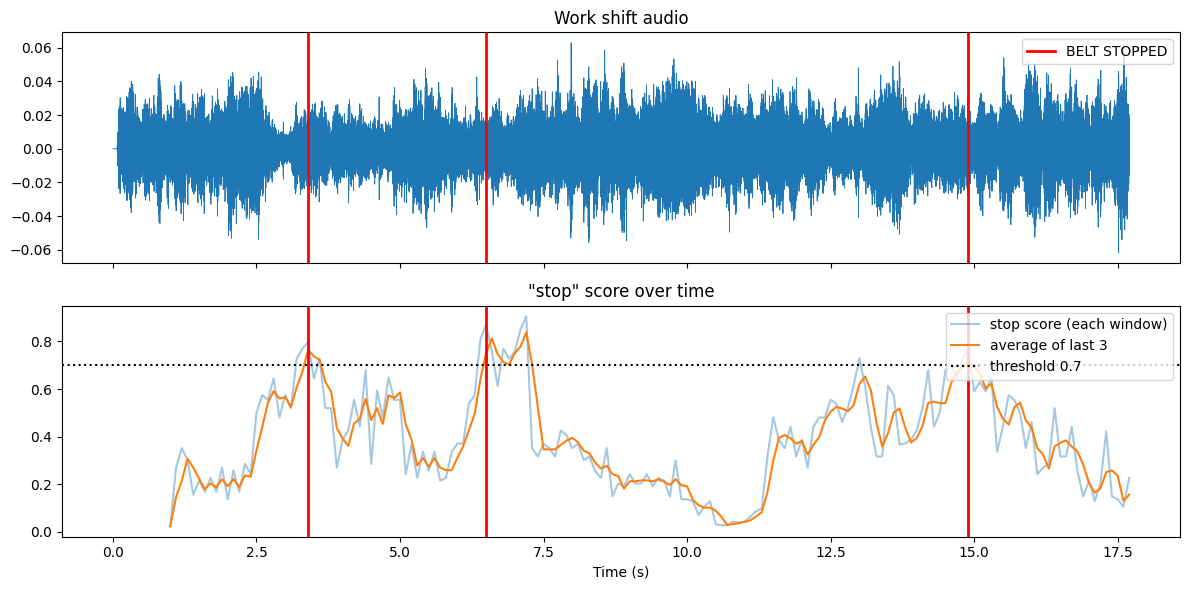

In [14]:
# time of the middle of each spoken "stop", read from the plot below, then run this cell again
STOP_TIMES = []     # for example [3.2, 7.9, 12.4]

t_audio = np.arange(len(shift_audio)) / SR
t_score = 1.0 + np.arange(len(probs_shift)) * HOP_S

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(t_audio, shift_audio, lw=0.6)
for k, t in enumerate(det_shift):
    axes[0].axvline(t, color="red", lw=2, label="BELT STOPPED" if k == 0 else None)
for k, t in enumerate(STOP_TIMES):
    axes[0].axvline(t, color="green", ls="--", lw=1, label="spoken stop" if k == 0 else None)
axes[0].set_title("Work shift audio")
axes[0].legend(loc="upper right")

axes[1].plot(t_score, probs_shift[:, 0], alpha=0.4, label="stop score (each window)")
axes[1].plot(t_score, smooth_shift, label="average of last 3")
axes[1].axhline(THRESHOLD, color="k", ls=":", label=f"threshold {THRESHOLD}")
for t in det_shift:
    axes[1].axvline(t, color="red", lw=2)
axes[1].set_xlabel("Time (s)")
axes[1].set_title('"stop" score over time')
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

if STOP_TIMES:
    print(score_stream(det_shift, STOP_TIMES))

- The system listens all the time with a 1 s window that moves every 100 ms, nobody has to press a button
- Top plot shows the audio, a red line is drawn where "BELT STOPPED" is shown. Bottom plot shows the raw stop score, the smoothed score and the 0.7 threshold
- Because of the refractory period, one shout gives one red line
- A 17.7 s work shift was recorded. The system showed BELT STOPPED three times, at 3.4 s, 6.5 s and 14.9 s, one red line for each rise of the score
- Smoothed score reached 0.75 to 0.84 at those times. There was one more rise around 13 s that peaked at about 0.65 and did not cross 0.7, so it was not detected
- The raw score is jumpy from window to window, and the average of the last 3 makes the curve smoother, so one noisy window does not trigger the belt
- `STOP_TIMES` was left empty, so the real recording could not be scored for misses and false stops

# 7 - Safety vs production: threshold tuning

- To compare thresholds fairly we also need a recording where we know exactly when stops happen, so we build a simulated 60 s work shift from unseen test clips: 8 "stop" clips, 14 other words and 2 pauses, with background noise on top
- The same sweep is also run on the real recording if `STOP_TIMES` is filled in

In [15]:
def build_sim_shift(seed=7):
    r = np.random.default_rng(seed)
    stop_pool = [b_audio[i] for i in np.where(b_labels == 0)[0][5:]]
    other_pool = [b_audio[i] for i in np.where(b_labels == 1)[0][5:]]

    audio = np.zeros(60 * SR, dtype=np.float32)
    kinds = ["stop"] * 8 + ["other"] * 14 + ["pause"] * 2
    r.shuffle(kinds)

    true_times = []
    for slot, kind in enumerate(kinds):                       # one clip every 2.5 s
        start = int(slot * 2.5 * SR)
        if kind == "stop":
            audio[start:start + SR] += stop_pool[len(true_times) % len(stop_pool)]
            true_times.append(slot * 2.5 + 0.5)
        elif kind == "other":
            audio[start:start + SR] += other_pool[r.integers(len(other_pool))]

    noise = np.concatenate([np.random.default_rng(100 + i).standard_normal(SR) for i in range(60)]).astype(np.float32)
    return np.clip(audio + 0.01 * noise, -1, 1), true_times

sim_audio, sim_true = build_sim_shift()
sim_probs = window_probs(sim_audio)

rows = []
for thr in [0.5, 0.7, 0.9]:
    det, _ = detect_stops(sim_probs[:, 0], thr=thr)
    rows.append({"threshold": thr, **score_stream(det, sim_true)})

sim_df = pd.DataFrame(rows)
print("Simulated 60 s work shift (unseen speakers + noise)")
print(sim_df.to_string(index=False))

Simulated 60 s work shift (unseen speakers + noise)
 threshold  stops spoken  detected  correct  misses  false stops
       0.5             8        12        8       0            4
       0.7             8        10        8       0            2
       0.9             8         8        8       0            0


In [16]:
if STOP_TIMES:
    rows = []
    for thr in [0.5, 0.7, 0.9]:
        det, _ = detect_stops(probs_shift[:, 0], thr=thr)
        rows.append({"threshold": thr, **score_stream(det, STOP_TIMES)})
    print("My recorded work shift")
    print(pd.DataFrame(rows).to_string(index=False))
else:
    print("Fill in STOP_TIMES in step 6 to run the sweep on the recorded shift")

Fill in STOP_TIMES in step 6 to run the sweep on the recorded shift


- Lower threshold: the belt reacts earlier and misses fewer stops, but more words are called stop (more false stops). Higher threshold: the opposite
- (fill in after running: which threshold is recommended, with the reason, considering that the safety officer wants zero misses and the production manager dislikes false stops)
- Simulated 60 s shift with 8 stops (unseen speakers, light noise):
  - threshold 0.5: 8 of 8 stops found, 0 misses, but 4 false stops
  - threshold 0.7: 8 of 8 stops found, 0 misses, 2 false stops
  - threshold 0.9: 8 of 8 stops found, 0 misses, 0 false stops
- A lower threshold gives more false stops, as expected. On this clean simulation 0.9 is perfect, but on the real microphone most stop scores were only between 0.5 and 0.7 (see the live table), so 0.9 would miss many real stops
- Live scores of the 10 close stops: 9 are at or above 0.5, 6 at or above 0.7 and 5 at or above 0.9
- **Recommendation: threshold 0.5**, because the safety officer wants zero misses and a missed stop is much worse than a false stop. Even so, 1 of the 10 close stops stayed below 0.5 (and 2 of 10 from 1 m), so no threshold is fully safe with this model. 0.7 is a compromise if the false stops cost too much

# 8 - Will it fit the chip? Performance

In [17]:
model_kb = os.path.getsize("kws_int8.tflite") / 1024

window = b_audio[0]
m_norm = (waveform_to_mfcc(tf.constant(window)).numpy() - MFCC_MEAN) / MFCC_STD

for _ in range(20):                                    # warm-up
    run_model(m_norm)

N = 200
start = time.perf_counter()
for _ in range(N):
    run_model(m_norm)
infer_ms = (time.perf_counter() - start) / N * 1000

start = time.perf_counter()
for _ in range(N):
    waveform_to_mfcc(tf.constant(window)).numpy()
mfcc_ms = (time.perf_counter() - start) / N * 1000

print(f"int8 model size        : {model_kb:.1f} KB  (limit 100 KB)")
print(f"Inference per window   : {infer_ms:.3f} ms")
print(f"MFCC for 1 s of audio  : {mfcc_ms:.3f} ms")

int8 model size        : 53.7 KB  (limit 100 KB)
Inference per window   : 0.229 ms
MFCC for 1 s of audio  : 12.212 ms


- Model size is checked against the 100 KB limit of the chip
- Inference time is the average of 200 runs of one window, MFCC time is the average of 200 runs for 1 s of audio
- These times are measured on the Colab CPU, a microcontroller is much slower, but the window moves only every 100 ms, so the time budget is large
- Model is 53.7 KB, so it fits the 100 KB limit with room to spare
- Inference takes 0.229 ms per window, which is below the 1 ms of the lab. MFCC takes 12.2 ms for 1 s of audio, so MFCC is about 50 times more expensive than the neural network
- A new window arrives every 100 ms and 0.229 + 12.2 ms is only about 12% of it, so the Colab CPU keeps up easily. A microcontroller is slower, so the MFCC part is the one to optimise

# 9 - Real factory conditions: robustness

- Repeat the live test from about 1 m away from the microphone, and then with a fan or machine sound playing in the background
- Same 10 stops and 10 other words each time

In [19]:
live_trials("stop", 10, "1 m away")
live_trials("other", 10, "1 m away")

[1 m away] trial 1/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.03)
[1 m away] trial 2/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   BELT STOPPED (max score 1.00)
[1 m away] trial 3/10: say 'STOP' in 3 2 1 -> speak now


...

   ignored (max score 0.48)
[1 m away] trial 9/10: say 'DOWN' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.65)
[1 m away] trial 10/10: say 'GO' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.65)


In [20]:
# play a fan or machine sound from another device, then run this cell
live_trials("stop", 10, "with noise")
live_trials("other", 10, "with noise")

[with noise] trial 1/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.53)
[with noise] trial 2/10: say 'STOP' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.67)
[with noise] trial 3/10: say 'STOP' in 3 2 1 -> speak now


...

   ignored (max score 0.59)
[with noise] trial 9/10: say 'DOWN' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.53)
[with noise] trial 10/10: say 'GO' in 3 2 1 -> speak now


<IPython.core.display.Javascript object>

   ignored (max score 0.60)


In [21]:
summary = live_summary(live_log)
summary["Lab 5 test accuracy (%)"] = cfg["lab5_test_accuracy_int8"]
summary

,condition,correct stops,missed stops,false stops,correct ignores,accuracy (%),Lab 5 test accuracy (%)
0,close,6,4,1,9,75.0,99.25
1,1 m away,6,4,3,7,65.0,99.25
2,with noise,2,8,1,9,55.0,99.25


- Table compares the live accuracy in every condition with the Lab 5 test accuracy
- (fill in after running: explanation for the manager of why the live accuracy is different from Lab 5)
- Live accuracy goes down in every harder condition: 75% close, 65% from 1 m and 55% with noise, against 99.25% in the Lab 5 test
- Stops caught: 6 of 10 close, 6 of 10 from 1 m and only 2 of 10 with noise. False stops: 1, 3 and 1. "shop" was a false stop in all three conditions, and "left" and "top" were false stops from 1 m
- Explanation for the manager: Lab 5 test clips come from the same dataset as the training clips (the same kind of microphones, close, one word per clip) and the silence class is synthetic. In the factory the laptop microphone is different, the voice is quieter from 1 m, and the fan noise adds sound that the model never heard in real form, so the stop score falls to 0.5-0.7 and falls under the threshold
- The fix is to collect real recordings from the factory (workers, distance, machine noise) and train again with them, and not to trust the test accuracy of a clean dataset

In [ ]:
# live trials counted again at different thresholds (uses the max score of every trial in live_log)
rows = []
for cond, g in live_log.groupby("condition", sort=False):
    for thr in [0.5, 0.7, 0.9]:
        s, o = g[g.expected == "stop"], g[g.expected == "other"]
        rows.append({"condition": cond, "threshold": thr,
                     "stops caught (of 10)": int((s["max score"] >= thr).sum()),
                     "false stops (of 10)": int((o["max score"] >= thr).sum())})
pd.DataFrame(rows)

- Same live trials, counted again at three thresholds. A lower threshold catches more stops and gives more false stops
- Values are taken from the recorded maximum score of every trial

# 10 - Report

- Model: int8, 53.7 KB, input 1 x 49 x 10 x 1 int8, output 3 classes
- Bench test: 14 of 15 correct. Workers' voices: only one phone clip was tested, so this part is incomplete
- Live trial: close 6 of 10 stops caught and 1 false stop, 1 m away 6 of 10 and 3 false stops, with noise 2 of 10 and 1 false stop
- Streaming: 3 BELT STOPPED detections in a 17.7 s shift, one for each shout that crossed the threshold
- Thresholds: 0.5 is recommended for safety, 0.9 had no false stops on the clean simulation but would miss many real stops
- Performance: 53.7 KB, 0.229 ms per window, 12.2 ms for MFCC of 1 s of audio
- Robustness: accuracy fell from 99.25% (Lab 5) to 75%, 65% and 55%, because of the different microphone, distance and noise